# Unit 7 Perceptron Activities
This notebook runs the three supplied perceptron notebooks in order, as the brief asks: the simple perceptron, the perceptron for the AND operator, and the multi-layer perceptron with the sigmoid function. I ran it in Google Colab.

## Scope and corrections
The original notebooks are unchanged; I worked on a copy, keeping their text and diagrams. I corrected them in six places. In Exercise 2, the weight update used the absolute error, which only works when the perceptron under-predicts; it now uses the signed error, and training stops after 100 epochs if the data cannot be learnt. In Exercise 3, one cell raises a shape error on purpose to teach the transpose; it now prints the error instead of stopping the run. The full training loop used `weights1`, a name never defined, so it failed on a fresh run; it now uses `weights_1`. The random starting weights now have a fixed seed, so the result is the same on every run. The error plot had only four points but an axis labelled in epochs; it now records the error every 1,000 epochs and plots it against the epoch. Two cells did arithmetic on numbers from a different run; they now use this run's own results, and a duplicated plot cell was removed.

After each exercise I add a short check of my own, to test what the example shows about the data.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 02 November 2026 at 10:37 UTC


In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
OUT = Path.cwd() / 'Unit7_ePortfolio_Exports'
OUT.mkdir(exist_ok=True)
SEED = 42
def save_figure(name):
    plt.gcf().savefig(OUT / name, dpi=180, bbox_inches='tight')
versions = {'numpy': np.__version__, 'matplotlib': matplotlib.__version__}
print('Package versions:', versions)

Package versions: {'numpy': '2.1.3', 'matplotlib': '3.10.0'}


## Part 1: Exercise 1, the simple perceptron (supplied)

### Author: Dr Mike Lakoju, CardiffMet

### We are re-implementing the last code. With Neural networks, most implementation uses large datasets, and it is important to write our code in a more optimized manner. We will be using Numpy Library to achieve this.

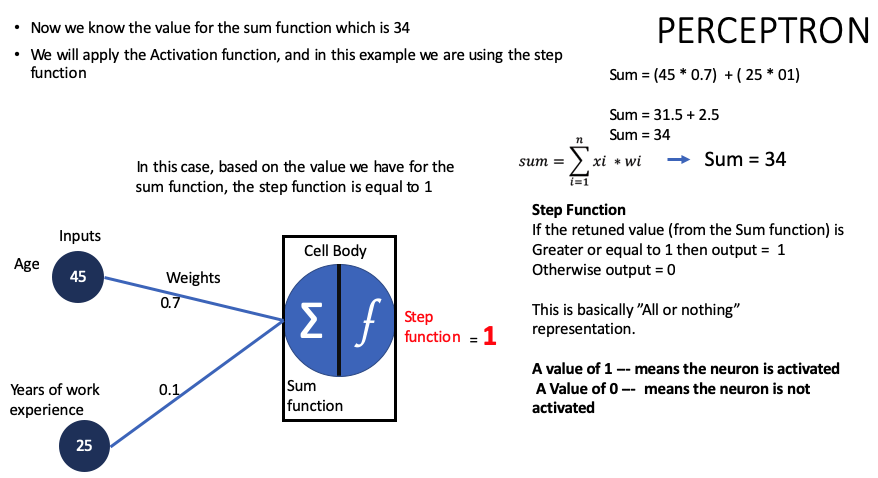

# Import Library


In [3]:
import numpy as np

# Lets define the Inputs and weights

With NumPy, we work with arrays. Hence we will need to define our inputs as arrays

In [4]:
inputs = np.array([45, 25])

In [5]:
# Check the type of the inputs

type(inputs)

numpy.ndarray

In [6]:
# check the value at index position 0
inputs[0]

np.int64(45)

# Lets define the weights

In [7]:
# creating the weights as Numpy array

weights = np.array([0.7, 0.1])

In [8]:
# Check the value at index 0

weights[0]

np.float64(0.7)

# Create the Sum Function


The dot function is called the dot product from linear algebra. If you are dealing with a huge dataset, The processing difference between the for loop used in the last notebook and this dot product will significantly be different.

In [9]:
def sum_func(inputs, weights):
    return inputs.dot(weights)


In [10]:
# for weights = [0.7, 0.1]

s_prob1 = sum_func(inputs, weights)
s_prob1

np.float64(34.0)

# Create Step function

In [11]:
def step_function(sum_func):
  if (sum_func >= 1):
    print(f'The Sum Function is greater than or equal to 1')
    return 1
  else:
        print(f'The Sum Function is NOT greater')
        return 0

### Result

In [12]:
step_function(s_prob1 )

The Sum Function is greater than or equal to 1


1

 ## If the is weights = [- 0.7, 0.1]

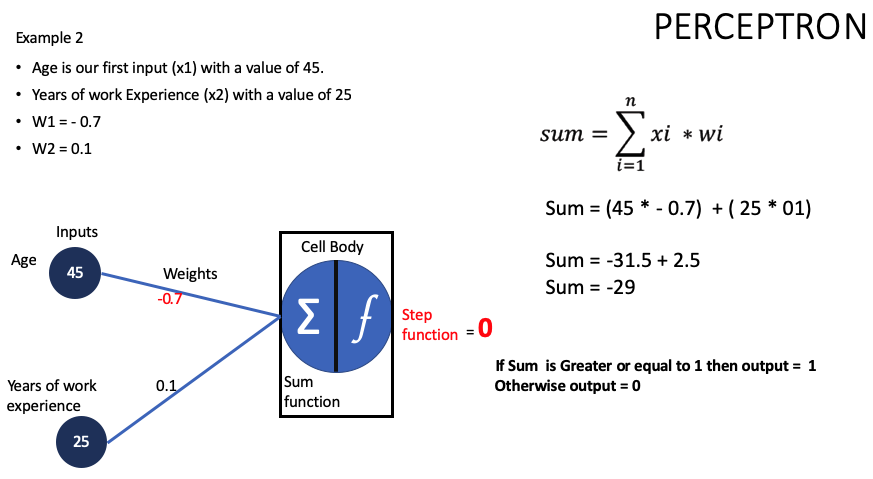

In [13]:
weights = [-0.7, 0.1]

In [14]:
# for weights = [- 0.7, 0.1]

s_prob2 = sum_func(inputs, weights)

round(s_prob2, 2)  #round to 2 decimal places

np.float64(-29.0)

### Result

In [15]:
step_function(s_prob2 )

The Sum Function is NOT greater


0

### By changing the input values and weights observe different results

### My check: the threshold of 1
The step function fires only when the weighted sum reaches 1, and the perceptron has no trainable bias. So the same inputs can switch the output just by scaling the weights.

In [16]:
for w in ([0.7, 0.1], [0.02, 0.01], [-0.7, 0.1], [0.0, 0.04]):
    s = np.array([45, 25]).dot(w)
    print(f'weights {w}: sum {s:.2f}, output {1 if s >= 1 else 0}')

weights [0.7, 0.1]: sum 34.00, output 1
weights [0.02, 0.01]: sum 1.15, output 1
weights [-0.7, 0.1]: sum -29.00, output 0
weights [0.0, 0.04]: sum 1.00, output 1


## Part 2: Exercise 2, the perceptron for the AND operator (supplied, corrected)

### Author: Dr Mike Lakoju, CardiffMet

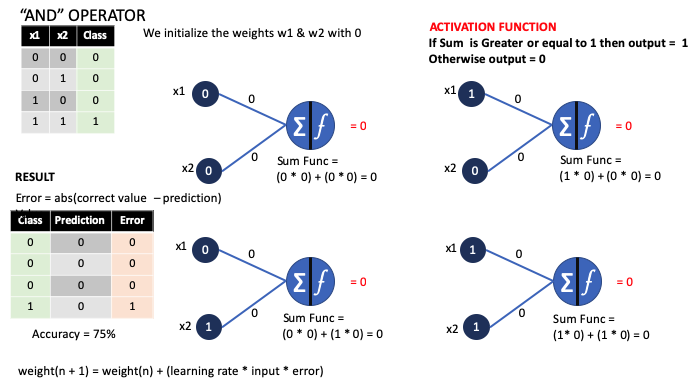

### Import Library

In [17]:
import numpy as np

### Define "Inputs, outputs and weights" as Numpy arrays

#### Inputs

In [18]:
# Creating input values as a matrix not as a vector
inputs = np.array([[0,0], [0,1], [1,0], [1,1]])

In [19]:
# Chcking the shape of the inputs

inputs.shape

(4, 2)

#### Outputs

In [20]:
outputs = np.array([0, 0, 0, 1])

In [21]:
#Checking the shape of the outputs

outputs.shape

(4,)

#### Weights

In [22]:
# one weight for x1 and one for x2
weights = np.array([0.0, 0.0])

#### Learning Rate

In [23]:
learning_rate = 0.1

## Step function

In [24]:
# This is our Activation function

def step_function(sum):
  if (sum >= 1):
    #print(f'The Sum of Weights is Greater or equal to 1')
    return 1
  else:
        #print(f'The Sum of Weights is NOT > or = to 1')
        return 0

## Process Output

<b>We define a function that allows us to calculate/ process the output. The function accepts an instance of our data, then calculate the sum function using Numpy. Finally, we check the output by passing it through the "Step Function."</b>

In [25]:
def cal_output(instance):
  sum_func = instance.dot(weights)
  return step_function(sum_func)

We pass it as alist in a numpy array ...

In [26]:
cal_output(np.array([[1,1]]))

0

## Train

In [27]:
# Check the number of outputs

len(outputs)

4

In [28]:
# Checking the index of the input at postion 3 ..
# this is the last inpute value
inputs[3]

array([1, 1])

In [29]:
inputs

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])

<b>Note that:</b> usually, we will need to define the number of epochs, because we will never really get a value of zero when dealing with real-world data. However, for this small data, we will run the loop till we obtain zero error

In [30]:
def train(max_epochs=100):
    total_error_value = 1
    epoch = 0
    # Stop when every row is right, or after max_epochs if the data cannot be learnt
    while (total_error_value != 0 and epoch < max_epochs):
        total_error_value = 0
        epoch += 1
        for i in range(len(outputs)):
            prediction = cal_output(inputs[i])
            # Signed error: positive raises the weights, negative lowers them
            error = outputs[i] - prediction
            total_error_value += abs(error)

            if error != 0:
                for j in range(len(weights)):
                    weights[j] = weights[j] + (learning_rate * inputs[i][j] * error)
                    print('Weight updated to: ' + str(weights[j]))
        print('Total error Value: ' + str(total_error_value))

In [31]:
train()

Weight updated to: 0.1
Weight updated to: 0.1
Total error Value: 1
Weight updated to: 0.2
Weight updated to: 0.2
Total error Value: 1
Weight updated to: 0.30000000000000004
Weight updated to: 0.30000000000000004
Total error Value: 1
Weight updated to: 0.4
Weight updated to: 0.4
Total error Value: 1
Weight updated to: 0.5
Weight updated to: 0.5
Total error Value: 1
Total error Value: 0


## Classification

In [32]:
# Now we have the final weights that will be used to classify new instances of the data after training.

weights

array([0.5, 0.5])

In [33]:
cal_output(np.array([0,0]))

0

In [34]:
cal_output(np.array([0,1]))

0

In [35]:
cal_output(np.array([1,0]))

0

In [36]:
cal_output(np.array([1,1]))

1

### My check: OR, NAND and XOR with the same perceptron
I train the same perceptron (threshold 1 with no trainable bias, signed error, learning rate 0.1, capped at 100 epochs and stopping earlier after a pass with no errors) on three other two-input operators. OR can be split by one straight line. XOR cannot, as the lecturecast shows. NAND can be split by a line, but it needs an output of 1 when both inputs are 0, which this perceptron cannot give without a bias.

In [37]:
def train_perceptron(targets, lr=0.1, max_epochs=100):
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    w = np.array([0.0, 0.0])
    for epoch in range(1, max_epochs + 1):
        total = 0
        for x, t in zip(X, targets):
            error = t - (1 if x.dot(w) >= 1 else 0)
            total += abs(error)
            w = w + lr * x * error
        if total == 0:
            return w, epoch, True
    return w, max_epochs, False

operators = {'AND': [0, 0, 0, 1], 'OR': [0, 1, 1, 1], 'NAND': [1, 1, 1, 0], 'XOR': [0, 1, 1, 0]}
perceptron_results = {}
for name, targets in operators.items():
    w, epochs_used, learnt = train_perceptron(targets)
    predictions = [1 if np.array(x).dot(w) >= 1 else 0 for x in [[0, 0], [0, 1], [1, 0], [1, 1]]]
    perceptron_results[name] = {'learnt': learnt, 'epochs': epochs_used, 'weights': w.round(2).tolist(),
                                'correct': int(sum(p == t for p, t in zip(predictions, targets)))}
    print(f"{name}: learnt {learnt} after {epochs_used} epochs; weights {w.round(2).tolist()}; {perceptron_results[name]['correct']} of 4 correct")

AND: learnt True after 6 epochs; weights [0.5, 0.5]; 4 of 4 correct
OR: learnt True after 10 epochs; weights [1.1, 1.1]; 4 of 4 correct
NAND: learnt False after 100 epochs; weights [0.4, 0.4]; 1 of 4 correct
XOR: learnt False after 100 epochs; weights [0.4, 0.4]; 2 of 4 correct


### My check: does a trainable bias fix NAND?
To test whether the missing bias, rather than the data, causes the NAND failure, I add a bias the perceptron can learn: a third input fixed at 1 with its own weight, and a threshold of 0. If NAND is now learnt while XOR still fails, the NAND failure came from the implementation and the XOR failure from the data.

In [38]:
def train_perceptron_bias(targets, lr=0.1, max_epochs=100):
    X = np.array([[0, 0, 1], [0, 1, 1], [1, 0, 1], [1, 1, 1]])  # third input is the bias, always 1
    w = np.array([0.0, 0.0, 0.0])
    for epoch in range(1, max_epochs + 1):
        total = 0
        for x, t in zip(X, targets):
            error = t - (1 if x.dot(w) >= 0 else 0)
            total += abs(error)
            w = w + lr * x * error
        if total == 0:
            return w, epoch, True
    return w, max_epochs, False

bias_results = {}
for name, targets in operators.items():
    w, epochs_used, learnt = train_perceptron_bias(targets)
    X = np.array([[0, 0, 1], [0, 1, 1], [1, 0, 1], [1, 1, 1]])
    correct = int(sum((1 if x.dot(w) >= 0 else 0) == t for x, t in zip(X, targets)))
    bias_results[name] = {'learnt': learnt, 'epochs': epochs_used, 'weights_and_bias': w.round(2).tolist(), 'correct': correct}
    print(f"{name} with a trainable bias: learnt {learnt} after {epochs_used} epochs; weights and bias {w.round(2).tolist()}; {correct} of 4 correct")

AND with a trainable bias: learnt True after 4 epochs; weights and bias [0.2, 0.1, -0.2]; 4 of 4 correct
OR with a trainable bias: learnt True after 4 epochs; weights and bias [0.1, 0.1, -0.1]; 4 of 4 correct
NAND with a trainable bias: learnt True after 6 epochs; weights and bias [-0.2, -0.1, 0.2]; 4 of 4 correct
XOR with a trainable bias: learnt False after 100 epochs; weights and bias [-0.1, 0.0, 0.0]; 2 of 4 correct


## Part 3: Exercise 3, the multi-layer perceptron with the sigmoid function (supplied, corrected)

### Author: Dr Mike Lakoju

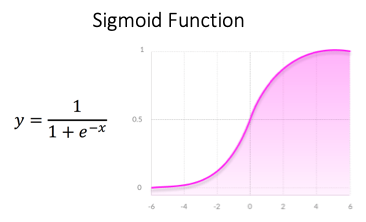

    * If X is high, the value is approximately 1
    * if X is small, the value is approximately 0

## Import Libraries

In [39]:
import numpy as np

## Define the Sigmoid Function

In [40]:
def sigmoid(sum_func):
  return 1 / (1 + np.exp(-sum_func))

In [41]:
sigmoid(0)

np.float64(0.5)

In [42]:
np.exp(2)

np.float64(7.38905609893065)

In [43]:
np.exp(1)

np.float64(2.718281828459045)

In [44]:
sigmoid(40)

np.float64(1.0)

In [45]:
sigmoid(-20.5)

np.float64(1.2501528648238605e-09)

# Input Layer to Hidden Layer

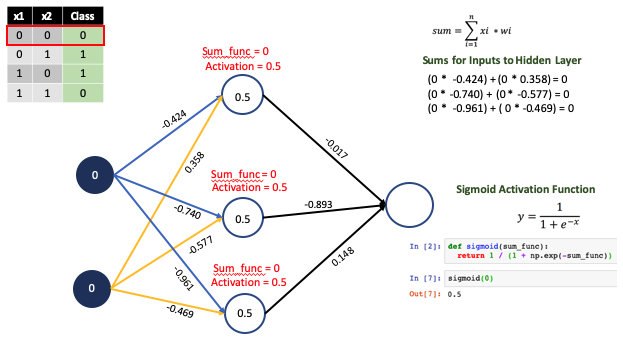

### Define "Inputs, outputs and weights" as Numpy arrays

#### Inputs

In [46]:
inputs = np.array([[0,0],
                   [0,1],
                   [1,0],
                   [1,1]])

In [47]:
inputs

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])

In [48]:
inputs.shape

(4, 2)

#### Outputs

In [49]:
outputs = np.array([[0],
                    [1],
                    [1],
                    [0]])

In [50]:
outputs.shape

(4, 1)

### Weights

#### These weights are for the connection between the inputs and the hidden layer

In [51]:
# First row holds the weights for x1, 2nd row contains the weights for x2

weights_0 = np.array([[-0.424, -0.740, -0.961],
                     [0.358, -0.577, -0.469]])
weights_0.shape

(2, 3)

#### These weights are for the connection between the  hidden layer and the output

In [52]:
weights_1 = np.array([[-0.017],
                     [-0.893],
                     [0.148]])
weights_1.shape

(3, 1)

#### Epochs & Learning Rate

In [53]:
epochs = 100
learning_rate = 0.3

In [54]:
#for epoch in epochs:

Dealing with the first side
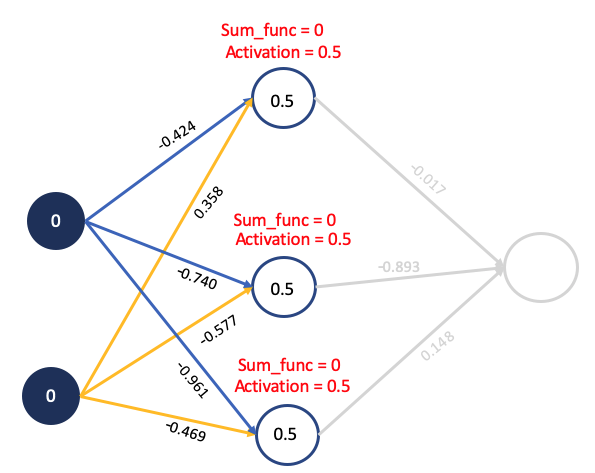

In [55]:
input_layer = inputs
input_layer

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])

In [56]:
# "sum_synapse_0" This holds the sum function total of weights for the hidden layer
# For the Output: Each row holds the sum_func for each input data  [0,0,0 -> data 0,0],[0.358, -0.577, -0.469 --> 0,1]
# The dot product does the matrix multiplication and also the sum

sum_synapse_0 = np.dot(input_layer, weights_0)
sum_synapse_0

array([[ 0.   ,  0.   ,  0.   ],
       [ 0.358, -0.577, -0.469],
       [-0.424, -0.74 , -0.961],
       [-0.066, -1.317, -1.43 ]])

In [57]:
# Computing the Sigmoid function for the Hidden layer

hidden_layer = sigmoid(sum_synapse_0)
hidden_layer

array([[0.5       , 0.5       , 0.5       ],
       [0.5885562 , 0.35962319, 0.38485296],
       [0.39555998, 0.32300414, 0.27667802],
       [0.48350599, 0.21131785, 0.19309868]])

Dealing with the 2nd side

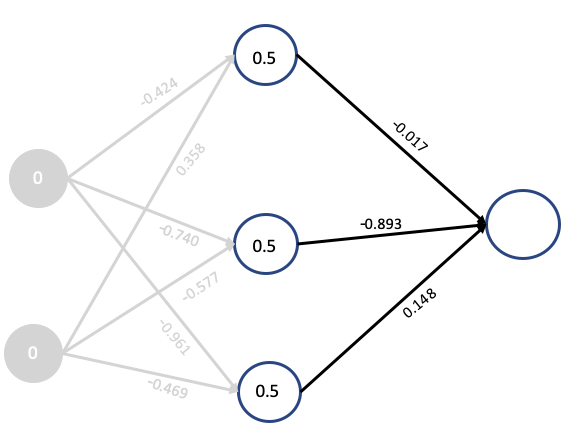

In [58]:
weights_1

array([[-0.017],
       [-0.893],
       [ 0.148]])

In [59]:
# "sum_synapse_1" This holds the sum function total of weights for the output layer
# For the Output: Each row holds the sum_func for each input data

sum_synapse_1 = np.dot(hidden_layer, weights_1)
sum_synapse_1

array([[-0.381     ],
       [-0.27419072],
       [-0.25421887],
       [-0.16834784]])

In [60]:
output_layer = sigmoid(sum_synapse_1)
output_layer

array([[0.40588573],
       [0.43187857],
       [0.43678536],
       [0.45801216]])


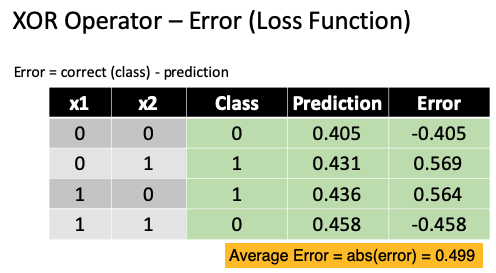

In [61]:
outputs

array([[0],
       [1],
       [1],
       [0]])

In [62]:
output_layer

array([[0.40588573],
       [0.43187857],
       [0.43678536],
       [0.45801216]])

In [63]:
error_output_layer = outputs - output_layer
error_output_layer

array([[-0.40588573],
       [ 0.56812143],
       [ 0.56321464],
       [-0.45801216]])

In [64]:
average_error = np.mean(abs(error_output_layer))
average_error

np.float64(0.49880848923713045)

Sigmoid Derivative
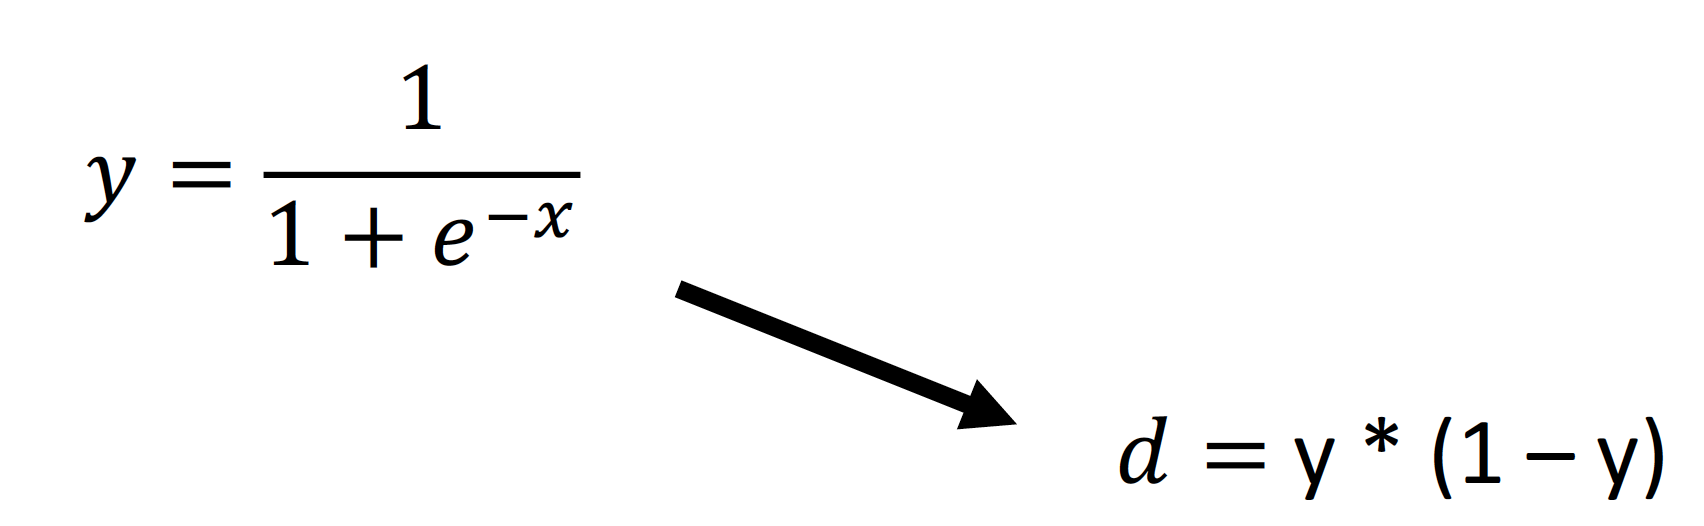

In [65]:
def sigmoid_derivative(sigmoid):
    return sigmoid * (1 - sigmoid)

# Delta output Calculation

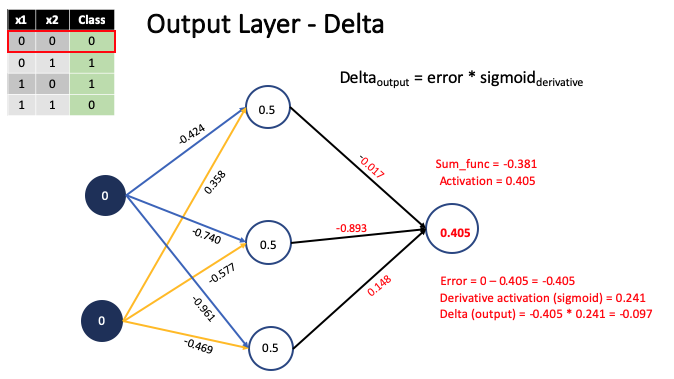

In [66]:
# output_layer holds the results of our application of the sigmoid, computed above

output_layer

array([[0.40588573],
       [0.43187857],
       [0.43678536],
       [0.45801216]])

In [67]:
# derivative_output is our Derivative of the activation function (sigmoid) which we have on the slide
# each row is for each instance of our input dataset

derivative_output = sigmoid_derivative(output_layer)
derivative_output

array([[0.2411425 ],
       [0.24535947],
       [0.24600391],
       [0.24823702]])

In [68]:
error_output_layer

array([[-0.40588573],
       [ 0.56812143],
       [ 0.56321464],
       [-0.45801216]])

In [69]:
# Delta output
# each row is for each instance of our input dataset

delta_output = error_output_layer * derivative_output
delta_output

array([[-0.0978763 ],
       [ 0.13939397],
       [ 0.138553  ],
       [-0.11369557]])

# Delta calculations for the Hidden Layer

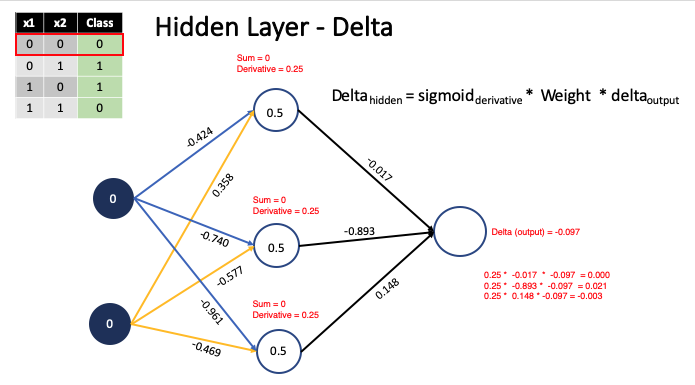

In [70]:
delta_output

array([[-0.0978763 ],
       [ 0.13939397],
       [ 0.138553  ],
       [-0.11369557]])

In [71]:
weights_1

array([[-0.017],
       [-0.893],
       [ 0.148]])

#### NOTE THAT:
    * Lets deal with this part first (Weight  * delta_output)
    * Notice that we will get an error below becuase of the shape of the weights_1  (Transpose)

In [72]:
# This line fails on purpose: the shapes (4, 1) and (3, 1) cannot be multiplied.
# I print the error so that the rest of the notebook still runs.
try:
    delta_output_x_weight = delta_output.dot(weights_1)
except ValueError as e:
    print('ValueError:', e)

ValueError: shapes (4,1) and (3,1) not aligned: 1 (dim 1) != 3 (dim 0)


In [73]:
weights_1.shape

(3, 1)

In [74]:
weights_1T = weights_1.T
weights_1T

array([[-0.017, -0.893,  0.148]])

In [75]:
weights_1T.shape

(1, 3)

#### Each one of the weights will have to be multiplied by each delta_output for each data instance     
       
       array([[-0.017],
             [-0.893],
             [ 0.148]])

In [76]:
delta_output_x_weight = delta_output.dot(weights_1T)
delta_output_x_weight

array([[ 0.0016639 ,  0.08740354, -0.01448569],
       [-0.0023697 , -0.12447882,  0.02063031],
       [-0.0023554 , -0.12372783,  0.02050584],
       [ 0.00193282,  0.10153015, -0.01682694]])

#### NOTE THAT:
    * Now we need to deal with the last part of the equation   
    * sigmoid_derivative * delta_output_x_weight

In [77]:
hidden_layer

array([[0.5       , 0.5       , 0.5       ],
       [0.5885562 , 0.35962319, 0.38485296],
       [0.39555998, 0.32300414, 0.27667802],
       [0.48350599, 0.21131785, 0.19309868]])

In [78]:
#  Each row in the output of delta_hidden_layer is for the data input values

delta_hidden_layer = delta_output_x_weight * sigmoid_derivative(hidden_layer)
delta_hidden_layer

array([[ 0.00041597,  0.02185088, -0.00362142],
       [-0.00057384, -0.02866677,  0.00488404],
       [-0.00056316, -0.02705587,  0.00410378],
       [ 0.00048268,  0.01692128, -0.00262183]])

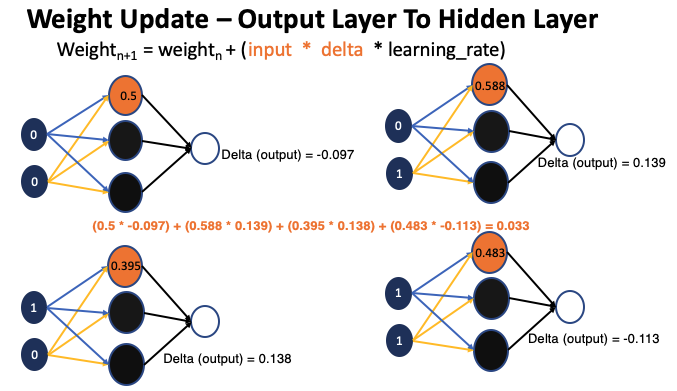

#### We will deal with the (input * delta) first
* The first column in "hidden_layer" holds  the activation value for the first neuron

In [79]:
hidden_layer

array([[0.5       , 0.5       , 0.5       ],
       [0.5885562 , 0.35962319, 0.38485296],
       [0.39555998, 0.32300414, 0.27667802],
       [0.48350599, 0.21131785, 0.19309868]])

In [80]:
delta_output

array([[-0.0978763 ],
       [ 0.13939397],
       [ 0.138553  ],
       [-0.11369557]])

* We need to multiply the "inputs" by "delta" however, for the matrix multiplication we need to transpose the values in the hidden_layer, so we have all of them on one row for each neuron

In [81]:
hidden_layerT = hidden_layer.T
hidden_layerT

array([[0.5       , 0.5885562 , 0.39555998, 0.48350599],
       [0.5       , 0.35962319, 0.32300414, 0.21131785],
       [0.5       , 0.38485296, 0.27667802, 0.19309868]])

In [82]:
input_x_delta1 = hidden_layerT.dot(delta_output)
input_x_delta1

array([[0.03293657],
       [0.02191844],
       [0.02108814]])

#### Let us now update the "weights_1"

In [83]:
weights_1 = weights_1 + (input_x_delta1 * learning_rate)
weights_1

array([[-0.00711903],
       [-0.88642447],
       [ 0.15432644]])

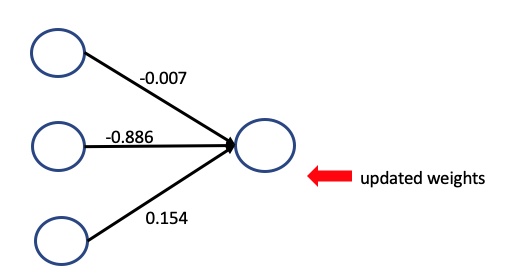

## Dealing with the Hidden Layer to Input Layer
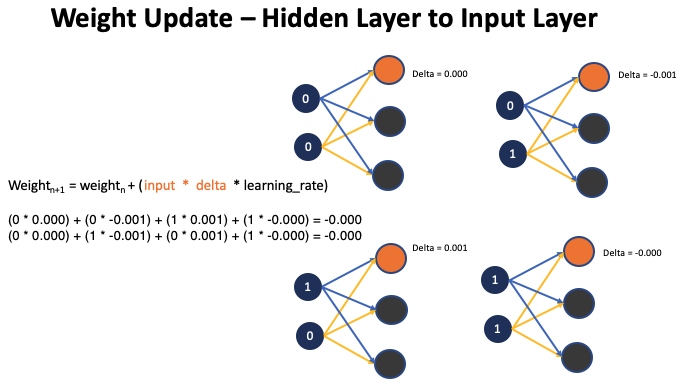

In [84]:
# First column is X1, and 2nd column is X2 (our input values )

input_layer

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])

In [85]:
delta_hidden_layer

array([[ 0.00041597,  0.02185088, -0.00362142],
       [-0.00057384, -0.02866677,  0.00488404],
       [-0.00056316, -0.02705587,  0.00410378],
       [ 0.00048268,  0.01692128, -0.00262183]])

In [86]:
# we need to transpose the values just as we did before

input_layerT = input_layer.T
input_layerT

array([[0, 0, 1, 1],
       [0, 1, 0, 1]])

In [87]:
input_x_delta0 = input_layerT.dot(delta_hidden_layer)
input_x_delta0

array([[-8.04778516e-05, -1.01345901e-02,  1.48194623e-03],
       [-9.11603819e-05, -1.17454886e-02,  2.26221011e-03]])

In [88]:
weights_0 = weights_0 + (input_x_delta0 * learning_rate)
weights_0

array([[-0.42402414, -0.74304038, -0.96055542],
       [ 0.35797265, -0.58052365, -0.46832134]])

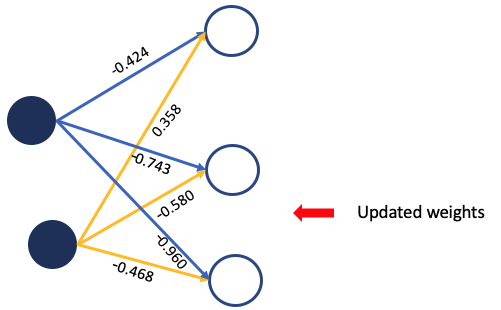

### So all the lines of code above, has allowed us to complete our first epoch. we will need to put all the code together so we can run multiple epochs

# Complete Artificial Neural Network

In [89]:
#Importing Numpy
import numpy as np

# This is the sigmoid Function
def sigmoid(sum):
  return 1 / (1 + np.exp(-sum))

#This is the sigmoid derivative as used before
def sigmoid_derivative(sigmoid):
  return sigmoid * (1 - sigmoid)

# Our input values
inputs = np.array([[0,0],
                   [0,1],
                   [1,0],
                   [1,1]])
#Our output values
outputs = np.array([[0],
                    [1],
                    [1],
                    [0]])

In [90]:
# weights_0 = np.array([[-0.424, -0.740, -0.961],
#                     [0.358, -0.577, -0.469]])

# weights_1 = np.array([[-0.017],
#                     [-0.893],
#                     [0.148]])

### Initializing our weights with random values
* <b>Note:</b> Multiplying the random number by 2 and subtracting by 1, allows us to have a mix of both positive and negative random numbers for the weights

In [91]:
np.random.seed(SEED)  # Fixed seed so the starting weights are the same on every run
weights_0 = 2 * np.random.random((2, 3)) - 1
weights_1 = 2 * np.random.random((3, 1)) - 1

In [92]:
epochs = 400000
learning_rate = 0.6
error = []

for epoch in range(epochs):
  input_layer = inputs
  sum_synapse0 = np.dot(input_layer, weights_0)
  hidden_layer = sigmoid(sum_synapse0)

  sum_synapse1 = np.dot(hidden_layer, weights_1)
  output_layer = sigmoid(sum_synapse1)

  error_output_layer = outputs - output_layer
  average = np.mean(abs(error_output_layer))
  # Record the error every 1,000 epochs for the plot, and print it every 100,000
  if epoch % 1000 == 0:
    error.append(average)
  if epoch % 100000 == 0:
    print('Epoch: ' + str(epoch + 1) + ' Error: ' + str(average))

  derivative_output = sigmoid_derivative(output_layer)
  delta_output = error_output_layer * derivative_output

  weights1T = weights_1.T  # The supplied code used weights1, which is never defined
  delta_output_weight = delta_output.dot(weights1T)
  delta_hidden_layer = delta_output_weight * sigmoid_derivative(hidden_layer)

  hidden_layerT = hidden_layer.T
  input_x_delta1 = hidden_layerT.dot(delta_output)
  weights_1 = weights_1 + (input_x_delta1 * learning_rate)

  input_layerT = input_layer.T
  input_x_delta0 = input_layerT.dot(delta_hidden_layer)
  weights_0 = weights_0 + (input_x_delta0 * learning_rate)
# The loop reports the error before its last update, so recompute it from the final weights
final_output_layer = sigmoid(np.dot(sigmoid(np.dot(inputs, weights_0)), weights_1))
average = np.mean(abs(outputs - final_output_layer))
print('Final mean absolute error (final weights): ' + str(average))

Epoch: 1 Error: 0.5003570780099351
Epoch: 100001 Error: 0.011572500263437854
Epoch: 200001 Error: 0.00806382738641219
Epoch: 300001 Error: 0.006546868640750788
Final mean absolute error (final weights): 0.005651962019392158


#### The mean absolute error after 400,000 epochs is very low.

In [93]:
# The supplied cells subtracted numbers from a different run. This uses this run's final error.
# 1 minus the mean absolute error is not an accuracy: it measures closeness to the targets, not the share classified correctly.
1 - average

np.float64(0.9943480379806079)

# Let's visualize this result

In [94]:
import matplotlib.pyplot as plt


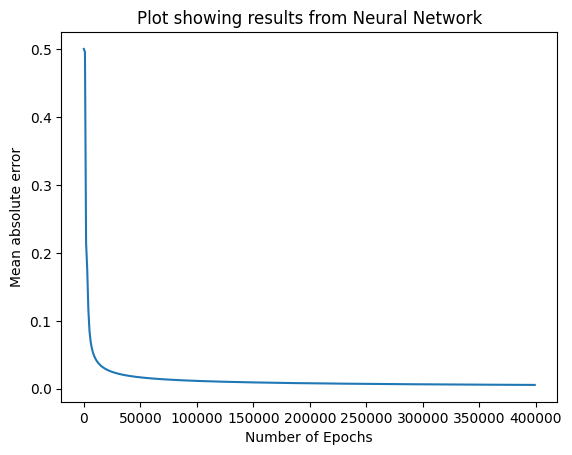

In [95]:
plt.xlabel('Number of Epochs')
plt.ylabel('Mean absolute error')
plt.title('Plot showing results from Neural Network')
plt.plot(np.arange(len(error)) * 1000, error)
save_figure('01_xor_training_error.png')
plt.show()

#### Compearing the outputs and the predictions

In [96]:
outputs

array([[0],
       [1],
       [1],
       [0]])

In [97]:
output_layer

array([[0.00443325],
       [0.99312187],
       [0.99420898],
       [0.00550548]])

#### * We see that our neural network was able to get values close to the actual values from the results.
#### * This shows that our neural network can handle the complexity of the XOR operator dataset.

* Let us see the updated weights. These are the weights we will require if we want to make future predictions

In [98]:
weights_0

array([[-6.89340856,  0.90748997, 11.45508877],
       [-7.777416  , -1.53997108, -5.74770354]])

In [99]:
weights_1

array([[-24.19150683],
       [ 28.49655019],
       [-15.13340448]])

In [100]:
# This function accepts an instance of a dataset

def calculate_output(instance):
    #input to hidden layer
    hidden_layer = sigmoid(np.dot(instance, weights_0))
    #hidden to output layer
    output_layer = sigmoid(np.dot(hidden_layer, weights_1))
    return output_layer[0]

In [101]:
round(calculate_output(np.array([0, 0])))

0

In [102]:
round(calculate_output(np.array([0, 1])))

1

In [103]:
round(calculate_output(np.array([1, 0])))

1

In [104]:
round(calculate_output(np.array([1, 1])))

0

### My check: how saturated is the trained network?
The sigmoid's slope, sigmoid(z)(1 - sigmoid(z)), is largest (0.25) when its output is 0.5 and close to 0 when the output is near 0 or 1. Backpropagation multiplies by this slope, so where units saturate, the weight updates become very small.

In [105]:
final_hidden = sigmoid(np.dot(inputs, weights_0))
final_output = sigmoid(np.dot(final_hidden, weights_1))
print('Largest output-layer slope:', round(float(sigmoid_derivative(final_output).max()), 4), '(the maximum possible is 0.25)')
print('Hidden activations below 0.05 or above 0.95:', int(((final_hidden < 0.05) | (final_hidden > 0.95)).sum()), 'of', final_hidden.size)
print('Largest absolute weight:', round(float(max(abs(weights_0).max(), abs(weights_1).max())), 2))
print('Error at epoch 100,001 and at the end:', round(error[100], 4), round(float(average), 4))

Largest output-layer slope: 0.0068 (the maximum possible is 0.25)
Hidden activations below 0.05 or above 0.95: 6 of 12
Largest absolute weight: 28.5
Error at epoch 100,001 and at the end: 0.0116 0.0057


### My check: does the network always learn XOR?
The supplied run starts from random weights. I train the same network from five different starting points (seeds 0 to 4), with 100,000 epochs each and the same learning rate of 0.6, and count how many of the four XOR rows each one gets right.

In [106]:
def train_mlp(seed, epochs=100000, lr=0.6):
    rng = np.random.default_rng(seed)
    w0 = 2 * rng.random((2, 3)) - 1
    w1 = 2 * rng.random((3, 1)) - 1
    for _ in range(epochs):
        hidden = sigmoid(inputs.dot(w0))
        out = sigmoid(hidden.dot(w1))
        delta_out = (outputs - out) * sigmoid_derivative(out)
        delta_hidden = delta_out.dot(w1.T) * sigmoid_derivative(hidden)
        w1 = w1 + hidden.T.dot(delta_out) * lr
        w0 = w0 + inputs.T.dot(delta_hidden) * lr
    out = sigmoid(sigmoid(inputs.dot(w0)).dot(w1))  # outputs from the final weights
    return out, float(np.mean(abs(outputs - out)))

seed_results = []
for seed in range(5):
    out, err = train_mlp(seed)
    correct = int((out.round() == outputs).sum())
    seed_results.append({'seed': seed, 'final_error': err, 'correct': correct, 'outputs': out.ravel().round(3).tolist()})
    print(f'seed {seed}: final mean absolute error {err:.4f}; {correct} of 4 correct; outputs {out.ravel().round(3).tolist()}')

seed 0: final mean absolute error 0.0173; 4 of 4 correct; outputs [0.022, 0.984, 0.984, 0.015]
seed 1: final mean absolute error 0.0076; 4 of 4 correct; outputs [0.013, 0.992, 0.992, 0.002]
seed 2: final mean absolute error 0.0114; 4 of 4 correct; outputs [0.009, 0.988, 0.986, 0.011]
seed 3: final mean absolute error 0.0188; 4 of 4 correct; outputs [0.02, 0.984, 0.984, 0.023]
seed 4: final mean absolute error 0.0169; 4 of 4 correct; outputs [0.021, 0.985, 0.984, 0.015]


In [107]:
results = {'run_by': 'Anne Dayer (student 39359)',
           'run_at_utc': datetime.now(timezone.utc).isoformat(timespec='minutes'),
           'execution_scope': 'Google Colab', 'packages': versions,
           'perceptron_operators': perceptron_results, 'perceptron_with_bias': bias_results,
           'xor_supplied_network': {'epochs': epochs, 'learning_rate': learning_rate,
                                    'final_error': float(average), 'outputs': final_output_layer.ravel().round(4).tolist()},
           'xor_seed_check': seed_results}
(OUT / 'Unit7_results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
print('Outputs saved to', OUT)

Outputs saved to /content/Unit7_ePortfolio_Exports


## Interpretation and limitations
A single perceptron draws one straight line, so it learnt AND and OR but could not learn XOR, which no single line can split. It also failed NAND, for a different reason: NAND is linearly separable, but with threshold 1 and no trainable bias this implementation always outputs 0 for (0, 0), although the lecturecast's neuron includes a bias. With a trainable bias added, the same rule learnt NAND, while XOR still failed. The multi-layer perceptron with the sigmoid function learnt XOR from every starting point I tried, but only by its outputs getting close to 0 and 1, after hundreds of thousands of epochs; how close they got varied with the starting weights. By the end, half the hidden activations and every output were close to 0 or 1, so each update changed the weights very little; Goodfellow, Bengio and Courville (2016) note that this is why sigmoid hidden units are now discouraged. The network has no biases either, yet its hidden layer still learnt features that separate XOR. Four rows of logic data cannot show whether a network generalises: there are no unseen examples to test it on.

## Sources
- Goodfellow, I., Bengio, Y. and Courville, A. (2016) *Deep Learning*. Cambridge, MA: MIT Press. Available at: https://www.deeplearningbook.org/ (Accessed: 2 November 2026).
- Géron, A. (2025) *Hands-On Machine Learning with Scikit-Learn and PyTorch*. Santa Rosa: O’Reilly.

Supplied materials: University of Essex Unit 7 e-Portfolio brief and the three notebooks by Dr Mike Lakoju, Cardiff Metropolitan University: simple_perceptron.ipynb, perceptron_AND_operator.ipynb and multi-layer Perceptron.ipynb.